# FI4008 Group 9: Harbour Energy plc (LSE: HBR)

This notebook runs `main.py` and then shows the key tables and figures. Everything is rebuilt from the saved data in `data/raw/`, so the numbers match the report exactly.

In [1]:
import os
os.chdir('..')          # run from the project folder
%run main.py

Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | matplotlib 3.11.2

--- 1. Data ---
All 7 raw files verified (downloaded 2026-11-22)
Bloomberg vs Yahoo Harbour prices since May 2021: largest gap 0.00%
Model table: 189 labelled months, 2011-01 to 2026-09; Harbour beat the FTSE 250 in 40.7% of them
Live row: 2026-10 (used to predict the following month)



--- 2. Market evidence ---
             company  window_years  ann_return_%  ann_volatility_%  max_drawdown_%  beta_vs_FTSE250
      Harbour Energy             1         43.41             41.48          -26.73            -0.47
FTSE 250 (benchmark)             1         13.92             15.94          -10.53             1.00
      Harbour Energy             3         14.88             41.18          -48.81             0.43
FTSE 250 (benchmark)             3         16.52             13.00          -10.53             1.00
      Harbour Energy             5          4.12             41.39          -61.87             0.06
FTSE 250 (benchmark)             5          4.42             15.06          -25.27             1.00



--- 3. Model ---
Train: 2011-01 to 2021-12 (132 months)
Test:  2022-01 to 2026-09 (57 months)
Chosen C = 10.0 (cross-validated AUC 0.530)
                     model  accuracy  balanced_accuracy  roc_auc  share_predicted_outperform
       Logistic regression     0.474              0.472     0.46                       0.474
Naive: always underperform     0.526              0.500     0.50                       0.000
               predicted: under  predicted: out
actual: under                15              15
actual: out                  15              12


     feature  coef_per_1sd  odds_ratio_per_1sd  coef_harbour_only_2021_2026  same_sign
    brent_1m         0.343               1.409                        0.305       True
    brent_3m        -0.312               0.732                       -0.065       True
      gas_1m         0.180               1.197                        0.150       True
hbr_mom_12_1        -0.094               0.910                       -0.168       True
  hbr_vol_6m        -0.091               0.913                       -0.099       True
     ftse_1m        -0.067               0.935                        0.500      False
   gbpusd_1m        -0.017               0.983                       -0.146       True
train_months                            132
test_months                              57
test_outperform_share              0.473684
chosen_C                               10.0
cv_auc                             0.530357
test_auc                           0.460494
test_auc_ci_low                    0.295


--- 4. Valuation ---


Discount rate: CAPM cost of equity 9.45% (gilt 5.24% + beta 0.84 x 5% premium); after-tax cost of debt 5.05%; equity 45% of capital -> WACC 7.0%. Bloomberg cost of equity 11.2%. We use 9%.
Realised vs market prices, Jan-Sep 2026: liquids 0.98 x Brent (avg $89.2), gas 1.01 x EU gas (avg $16.9)
After-tax decommissioning at our rate: $1,835m
DCF enterprise value $14,736m -> 211p a share (7%: 245p, 11%: 180p)


                                      -20%   -10%    +0%   +10%   +20%
WACC \ oil and gas prices vs futures                                  
7%                                     0.0  106.0  245.0  385.0  524.0
8%                                     0.0   96.0  228.0  360.0  492.0
9%                                     0.0   85.0  211.0  337.0  462.0
10%                                    0.0   75.0  195.0  315.0  434.0
11%                                    0.0   65.0  180.0  294.0  408.0
                                                      scenario  cum_production_mmboe  ev_usd_m  pence  upside_%
Base case (futures prices, plateau to 2030, -12% a year after)                  1872     14736    211     -15.7
 Harbour's own long-term prices from 2029 ($75 Brent, $11 gas)                  1872     16606    291      16.2
   Growth case: LLOG + Mexico hold plateau to 2032, -10% after                  2320     17086    312      24.6
                                             Both of th

Break-even: the DCF equals 250.4p when prices are 3.1% above the futures curve
Comparables 2026e p25: 1.19x EBITDA -> 153p
Comparables 2026e median: 2.08x EBITDA -> 525p
Comparables 2026e p75: 2.35x EBITDA -> 637p
Comparables 2027e p25: 1.28x EBITDA -> 127p
Comparables 2027e median: 1.42x EBITDA -> 180p
Comparables 2027e p75: 2.23x EBITDA -> 480p
Precedents low: $7.9 per 2P barrel -> 102p
Precedents median: $9.5 per 2P barrel -> 189p
Precedents high: $12.3 per 2P barrel -> 332p
Cross-check: $44.7k per flowing boe/d -> 665p
LBO: 272p at a 20% return (25%: 240p, 15%: 313p)
  LBO at a 1.42x exit: 214p
  LBO at a 3.03x exit: 375p
Equal weights would give 213p
                        base_p  low_p  high_p  weight  upside_%
DCF / NAV                211.0  179.6   245.5    0.40     -15.7
Trading comparables      180.1  127.1   479.6    0.25     -28.1
Precedent transactions   188.8  102.3   331.6    0.20     -24.6
LBO                      272.3  240.3   313.4    0.15       8.7
Blended (team we

## 1. Share-price record (Table T02)
Harbour vs the FTSE 250 over 1, 3 and 5 years.

In [2]:
import pandas as pd
from IPython.display import Image, display
risk = pd.read_csv('tables/T02_risk_return.csv')
risk[risk['company'].isin(['Harbour Energy', 'FTSE 250 (benchmark)'])]

,company,window_years,ann_return_%,ann_volatility_%,max_drawdown_%,beta_vs_FTSE250
0,Harbour Energy,1,43.41,41.48,-26.73,-0.47
1,FTSE 250 (benchmark),1,13.92,15.94,-10.53,1.00
12,Harbour Energy,3,14.88,41.18,-48.81,0.43
13,FTSE 250 (benchmark),3,16.52,13.00,-10.53,1.00
24,Harbour Energy,5,4.12,41.39,-61.87,0.06
25,FTSE 250 (benchmark),5,4.42,15.06,-25.27,1.00


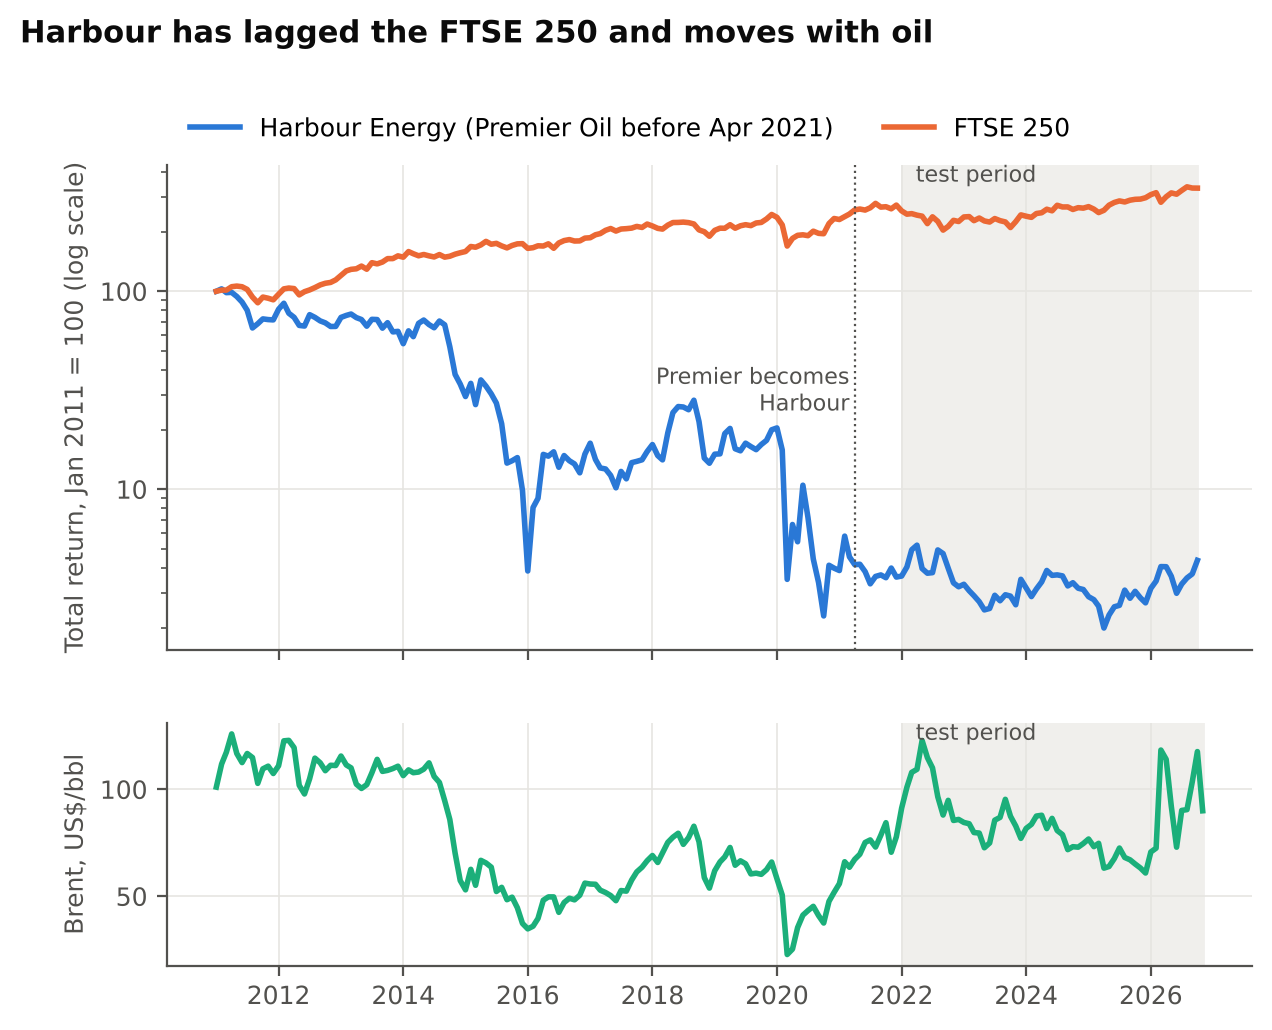

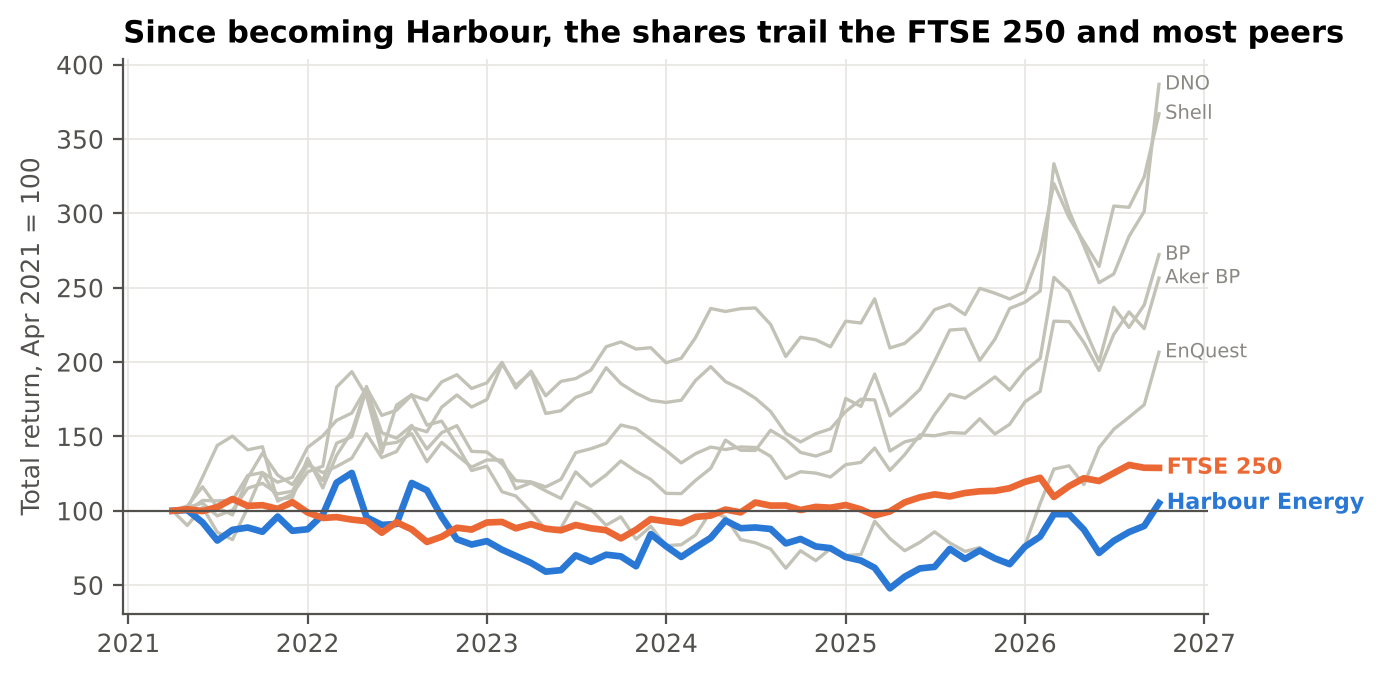

In [3]:
display(Image('figures/F01_prices.png', width=650))
display(Image('figures/F02_relative_performance.png', width=650))

## 2. Machine-learning model
Test results, coefficients and the placebo check.

In [4]:
pd.read_csv('tables/T10_model_summary.csv', index_col=0)

,value
train_months,132
test_months,57
test_outperform_share,0.47368421052631576
chosen_C,10.0
cv_auc,0.5303571428571429
test_auc,0.4604938271604938
test_auc_ci_low,0.29556370353784145
test_auc_ci_high,0.6111559139784944
test_accuracy,0.47368421052631576
naive_accuracy,0.5263157894736842


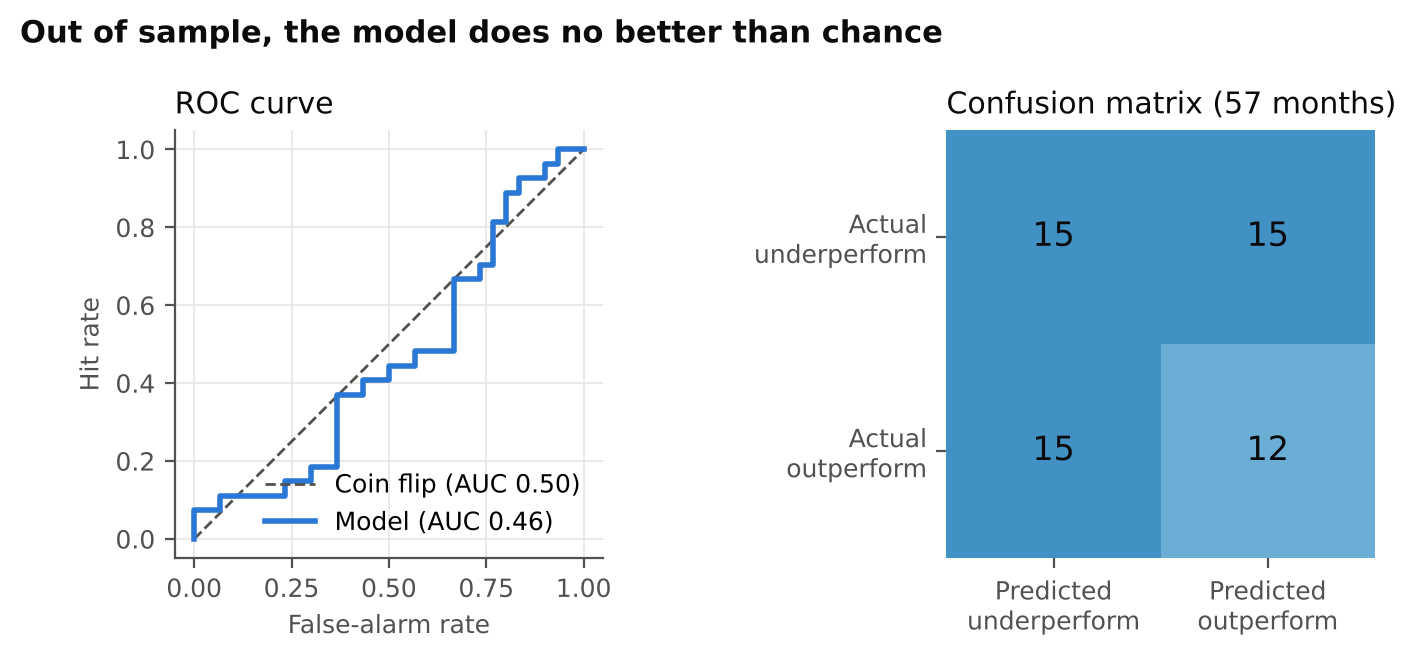

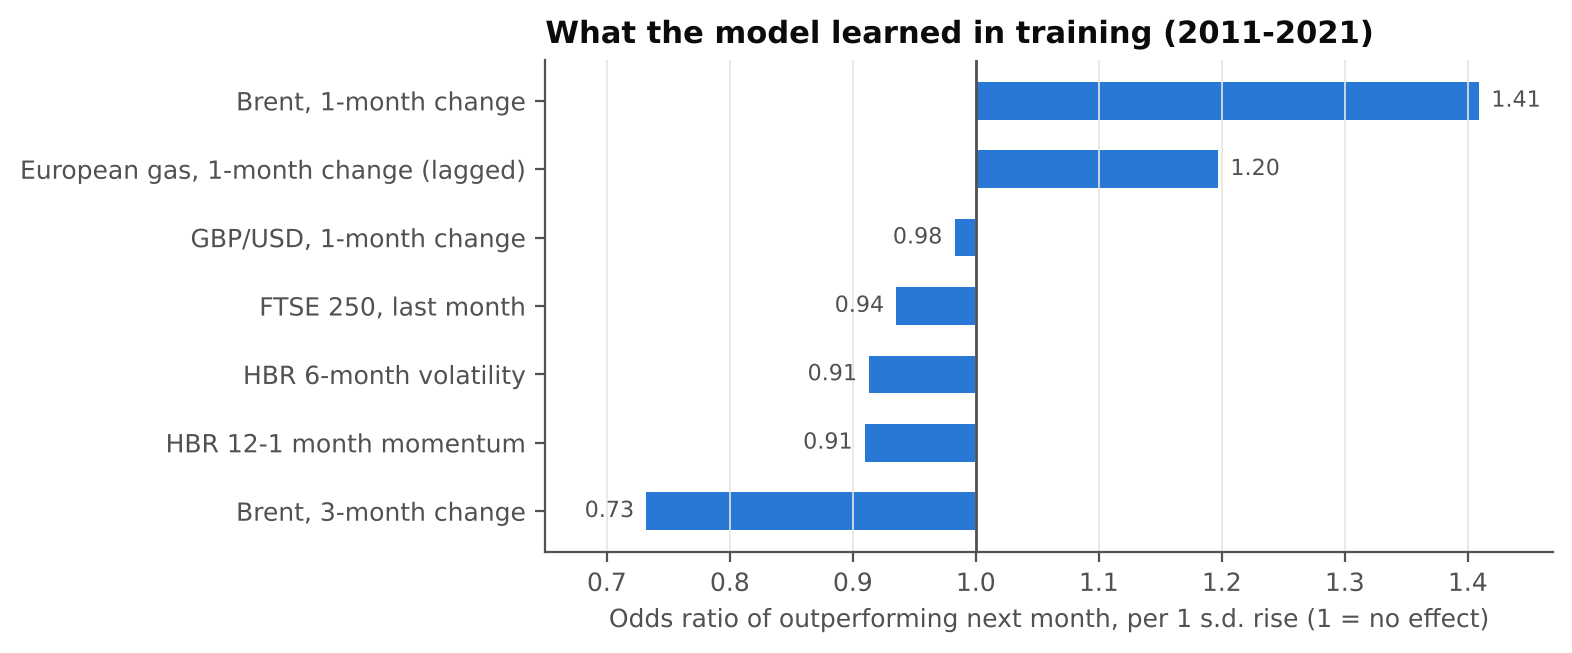

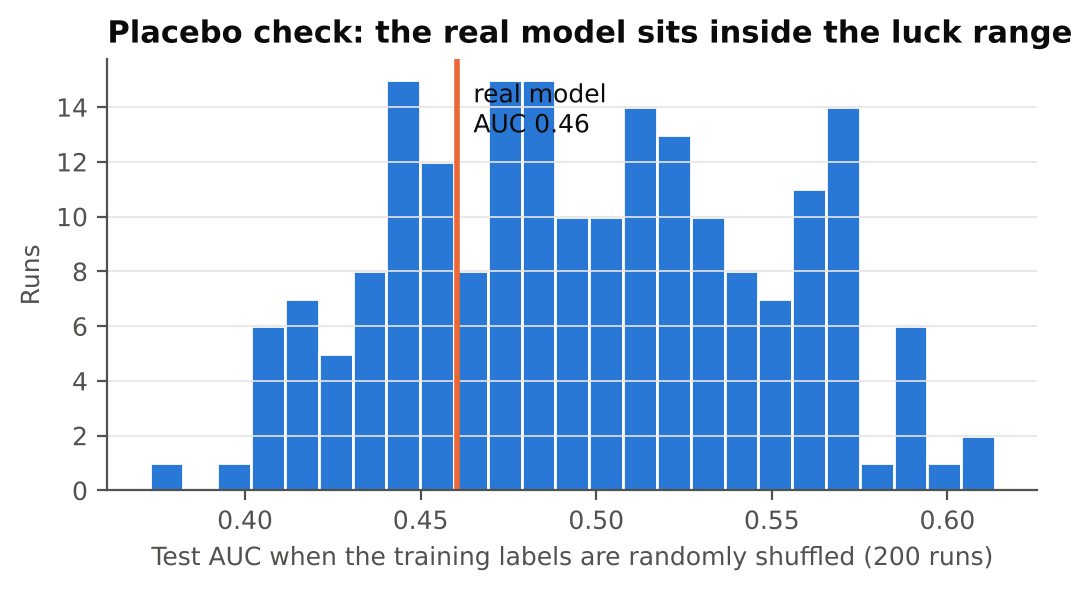

In [5]:
display(Image('figures/F03_test_results.png', width=650))
display(Image('figures/F04_coefficients.png', width=600))
display(Image('figures/F05_placebo.png', width=600))

## 3. Valuation
The four methods and the blended target price (pence per share; share price 250.4p).

In [6]:
pd.read_csv('tables/T17_valuation_summary.csv', index_col=0)

,base_p,low_p,high_p,weight,upside_%
DCF / NAV,211.0,179.6,245.5,0.40,-15.7
Trading comparables,180.1,127.1,479.6,0.25,-28.1
Precedent transactions,188.8,102.3,331.6,0.20,-24.6
LBO,272.3,240.3,313.4,0.15,8.7
Blended (team weights),208.0,160.1,331.4,1.00,-16.9


In [7]:
pd.read_csv('tables/T16_dcf_scenarios.csv')

,scenario,cum_production_mmboe,ev_usd_m,pence,upside_%
0,"Base case (futures prices, plateau to 2030, -1...",1872,14736,211,-15.7
1,Harbour's own long-term prices from 2029 ($75 ...,1872,16606,291,16.2
2,Growth case: LLOG + Mexico hold plateau to 203...,2320,17086,312,24.6
3,Both of the above,2320,19512,417,66.5
4,Prices 10% below futures,1872,11819,85,-66.1


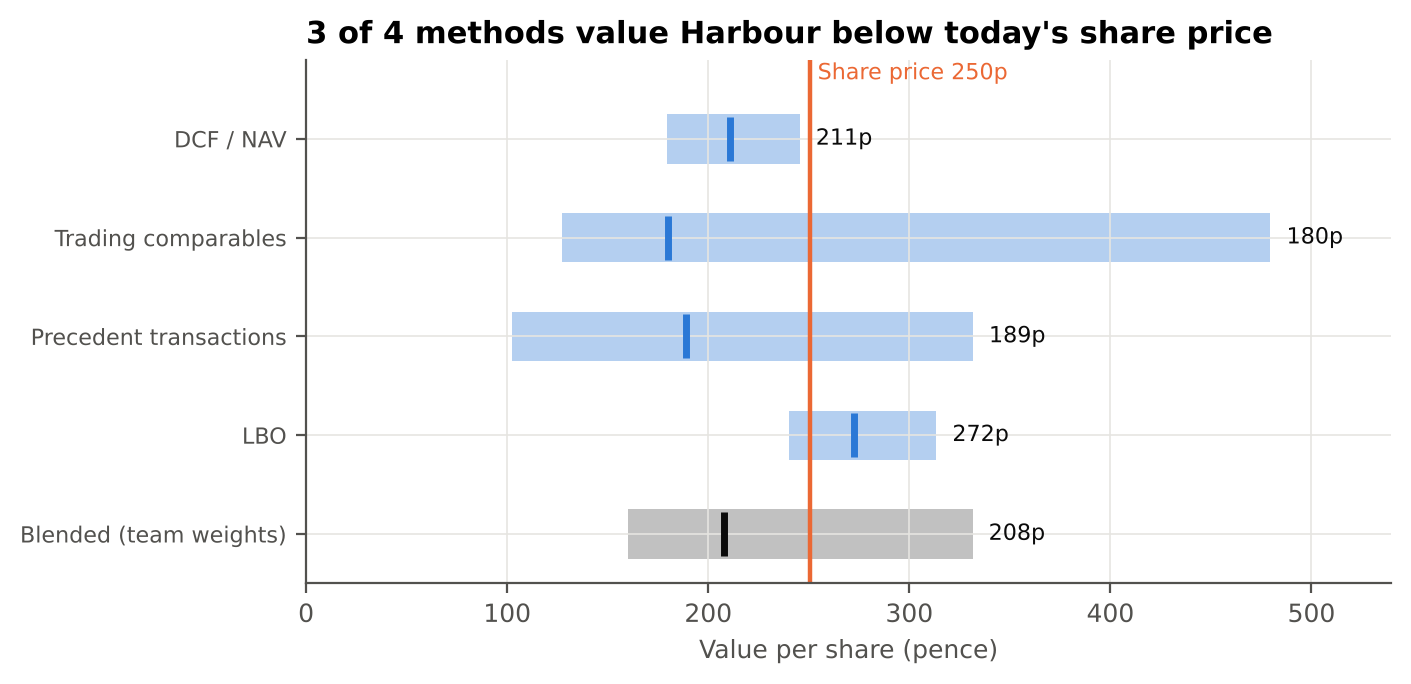

In [8]:
display(Image('figures/F06_football_field.png', width=650))